In [70]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text
from sklearn.metrics import r2_score, mean_absolute_error

In [71]:
df = pd.read_csv("CarPrice_Assignment.csv")

In [72]:
df

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,carheight,curbweight,enginetype,cylindernumber,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,201,-1,volvo 145e (sw),gas,std,four,sedan,rwd,front,109.1,188.8,68.9,55.5,2952,ohc,four,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845.0
201,202,-1,volvo 144ea,gas,turbo,four,sedan,rwd,front,109.1,188.8,68.8,55.5,3049,ohc,four,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045.0
202,203,-1,volvo 244dl,gas,std,four,sedan,rwd,front,109.1,188.8,68.9,55.5,3012,ohcv,six,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485.0
203,204,-1,volvo 246,diesel,turbo,four,sedan,rwd,front,109.1,188.8,68.9,55.5,3217,ohc,six,145,idi,3.01,3.40,23.0,106,4800,26,27,22470.0


In [73]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cylindernumber    205 non-null    object 
 16  enginesize        205 non-null    int64  
 1

In [74]:
df.describe()

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


In [75]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cylindernumber    205 non-null    object 
 16  enginesize        205 non-null    int64  
 1

In [76]:
text_cols = [ "CarName","fueltype", "aspiration", "doornumber", "carbody", "drivewheel", "enginelocation", "enginetype", "cylindernumber", "fuelsystem"]

overview = pd.DataFrame({
    "column": text_cols,
    "n_categories": [df[c].nunique() for c in text_cols],
    "categories": [" | ".join(sorted(df[c].unique())) for c in text_cols],
})
overview

,column,n_categories,categories
0,CarName,147,Nissan versa | alfa-romero Quadrifoglio | alfa...
1,fueltype,2,diesel | gas
2,aspiration,2,std | turbo
3,doornumber,2,four | two
4,carbody,5,convertible | hardtop | hatchback | sedan | wagon
5,drivewheel,3,4wd | fwd | rwd
6,enginelocation,2,front | rear
7,enginetype,7,dohc | dohcv | l | ohc | ohcf | ohcv | rotor
8,cylindernumber,7,eight | five | four | six | three | twelve | two
9,fuelsystem,8,1bbl | 2bbl | 4bbl | idi | mfi | mpfi | spdi |...


C:\Users\chris\AppData\Local\Temp\ipykernel_1208\1027606059.py:12: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


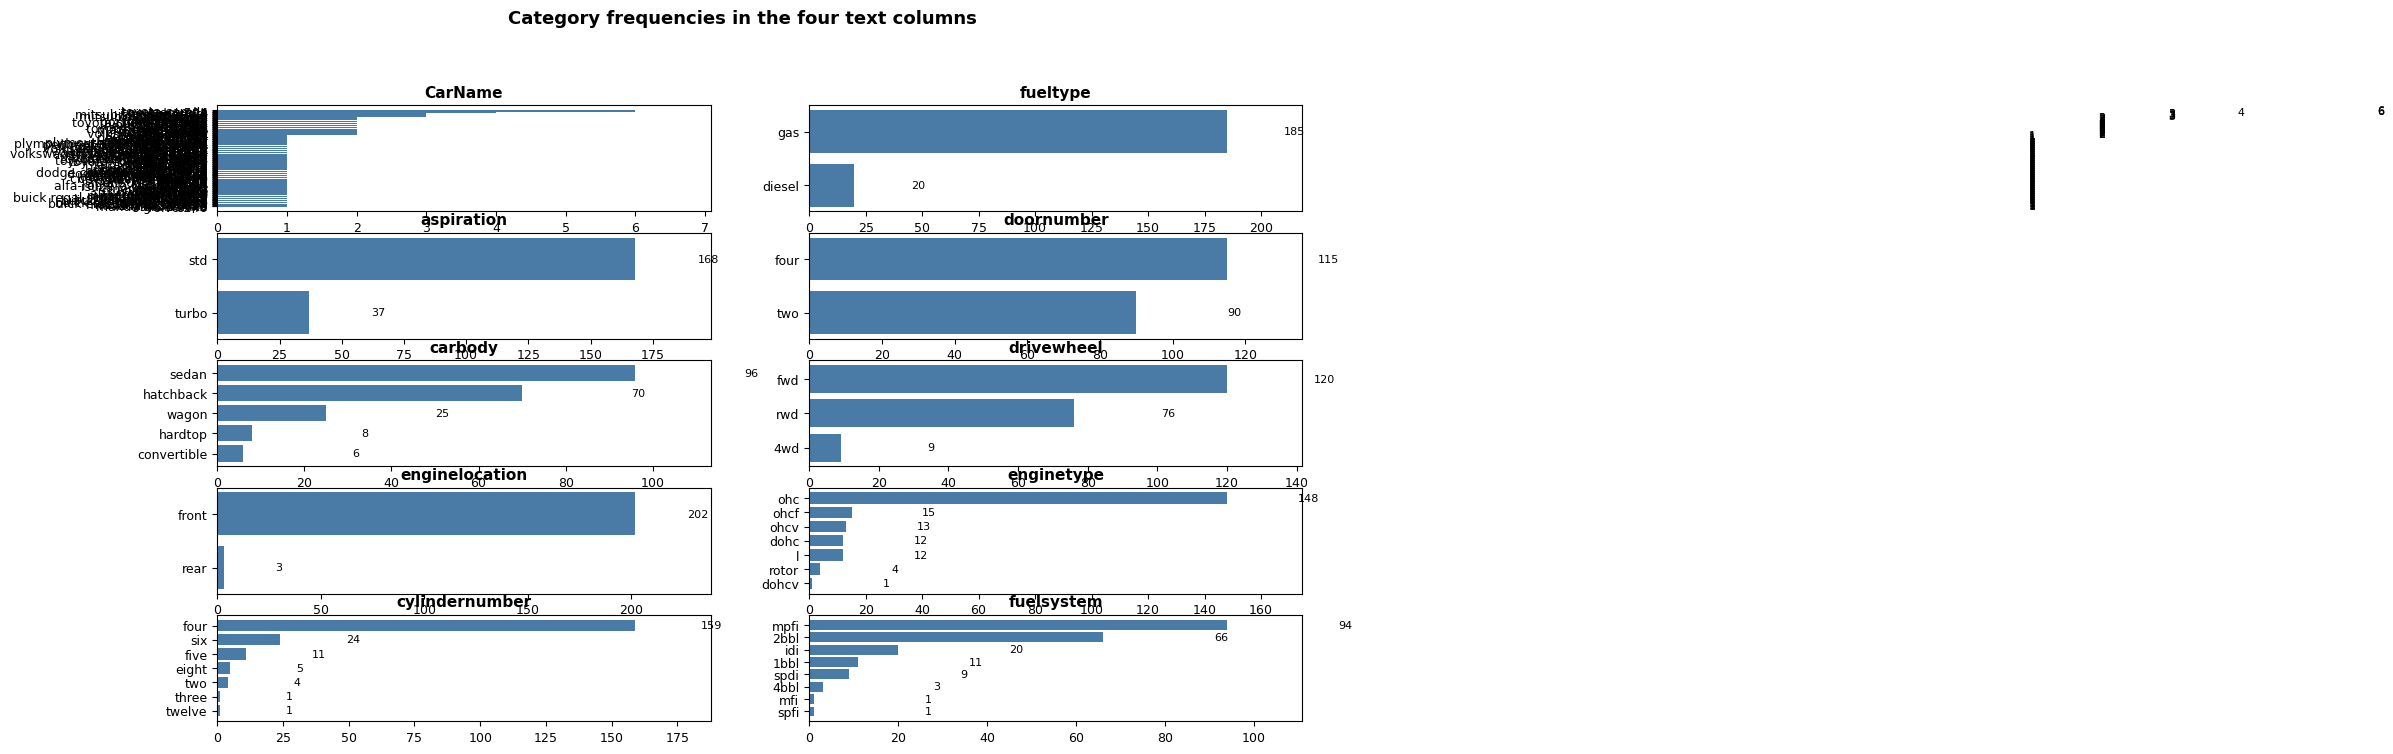

In [77]:
fig, axes = plt.subplots(5, 2, figsize=(14, 8))
for ax, col in zip(axes.ravel(), text_cols):
    vc = df[col].value_counts()
    ax.barh(vc.index[::-1], vc.values[::-1], color="#4a7ba7")
    for i, v in enumerate(vc.values[::-1]):
        ax.text(v + 25, i, f"{v:,}", va="center", fontsize=8)
    ax.set_title(col, fontsize=11, fontweight="bold")
    ax.set_xlim(0, vc.max() * 1.18)
    ax.tick_params(labelsize=9)
fig.suptitle("Category frequencies in the four text columns",
             fontsize=13, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

In [78]:
# .str.split(" ") chops the name at every space; .str[0] keeps the first piece.
df["brand"] = df["CarName"].str.split(" ").str[0].str.lower()

print("Brands we found:", df["brand"].nunique())
print()
print(df["brand"].value_counts().to_string())

Brands we found: 27

brand
toyota         31
nissan         18
mazda          15
honda          13
mitsubishi     13
subaru         12
peugeot        11
volvo          11
dodge           9
volkswagen      9
bmw             8
buick           8
audi            7
plymouth        7
saab            6
isuzu           4
porsche         4
alfa-romero     3
jaguar          3
chevrolet       3
vw              2
maxda           2
renault         2
toyouta         1
vokswagen       1
mercury         1
porcshce        1


In [79]:
CYLINDER_RANK = {
    "two" : 0,
    "three" : 1,
    "four" : 2,
    "five" : 3,
    "six" : 4,
    "eight" : 5,
    "twelve" : 6

}

df_enc = df.copy()
df_enc["cylindernumber_rank"] = df_enc["cylindernumber"].map(CYLINDER_RANK)

# Any unmapped value would become NaN - check before moving on.
assert df_enc["cylindernumber_rank"].notna().all(), "unmapped chronotype value found"

print(df_enc[["cylindernumber", "cylindernumber_rank"]].drop_duplicates().sort_values("cylindernumber_rank"))

   cylindernumber  cylindernumber_rank
55            two                    0
18          three                    1
0            four                    2
4            five                    3
2             six                    4
71          eight                    5
49         twelve                    6


In [80]:
onehot_cols = ["brand", "fueltype", "aspiration", "doornumber", "carbody", "drivewheel", "enginelocation", "enginetype", "fuelsystem"]

dummies = pd.get_dummies(
    df_enc[onehot_cols],
    drop_first=True,
).astype(int)        # get_dummies gives bool; cast to int so coefficients read cleanly

print(f"{len(onehot_cols)} columns -> {dummies.shape[1]} dummy columns\n")
for col in onehot_cols:
    produced = [c for c in dummies.columns if c.startswith(col + "_")]
    baseline = sorted(set(df_enc[col].unique()) - {c[len(col) + 1:] for c in produced})
    print(f"{col}")
    print(f"   baseline (dropped): {baseline[0]}")
    print(f"   kept as columns   : {[c for c in produced]}")
print()
dummies.head()

9 columns -> 49 dummy columns

brand
   baseline (dropped): alfa-romero
   kept as columns   : ['brand_audi', 'brand_bmw', 'brand_buick', 'brand_chevrolet', 'brand_dodge', 'brand_honda', 'brand_isuzu', 'brand_jaguar', 'brand_maxda', 'brand_mazda', 'brand_mercury', 'brand_mitsubishi', 'brand_nissan', 'brand_peugeot', 'brand_plymouth', 'brand_porcshce', 'brand_porsche', 'brand_renault', 'brand_saab', 'brand_subaru', 'brand_toyota', 'brand_toyouta', 'brand_vokswagen', 'brand_volkswagen', 'brand_volvo', 'brand_vw']
fueltype
   baseline (dropped): diesel
   kept as columns   : ['fueltype_gas']
aspiration
   baseline (dropped): std
   kept as columns   : ['aspiration_turbo']
doornumber
   baseline (dropped): four
   kept as columns   : ['doornumber_two']
carbody
   baseline (dropped): convertible
   kept as columns   : ['carbody_hardtop', 'carbody_hatchback', 'carbody_sedan', 'carbody_wagon']
drivewheel
   baseline (dropped): 4wd
   kept as columns   : ['drivewheel_fwd', 'drivewheel_rwd']
en

,brand_audi,brand_bmw,brand_buick,brand_chevrolet,brand_dodge,brand_honda,brand_isuzu,brand_jaguar,brand_maxda,brand_mazda,brand_mercury,brand_mitsubishi,brand_nissan,brand_peugeot,brand_plymouth,brand_porcshce,brand_porsche,brand_renault,brand_saab,brand_subaru,brand_toyota,brand_toyouta,brand_vokswagen,brand_volkswagen,brand_volvo,brand_vw,fueltype_gas,aspiration_turbo,doornumber_two,carbody_hardtop,carbody_hatchback,carbody_sedan,carbody_wagon,drivewheel_fwd,drivewheel_rwd,enginelocation_rear,enginetype_dohcv,enginetype_l,enginetype_ohc,enginetype_ohcf,enginetype_ohcv,enginetype_rotor,fuelsystem_2bbl,fuelsystem_4bbl,fuelsystem_idi,fuelsystem_mfi,fuelsystem_mpfi,fuelsystem_spdi,fuelsystem_spfi
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0
3,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0
4,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0


In [81]:
TARGET = "price"
ID_COLS = ["car_ID"]

In [82]:
numeric_cols = [
    c for c in df.columns
    if c not in ID_COLS + text_cols + [TARGET]
    and df[c].dtype != "object"
]

X = pd.concat(
    [
        df_enc[numeric_cols],              # 11 - identical to Notebook 1
        df_enc[["cylindernumber_rank"]],       #  1 - ordinal
        dummies,                           # 11 - one-hot
    ],
    axis=1,
)
Y = df_enc[TARGET].copy()

In [83]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25)

In [84]:
model = DecisionTreeRegressor()

In [85]:
model

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [86]:
model.fit(X_train, Y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


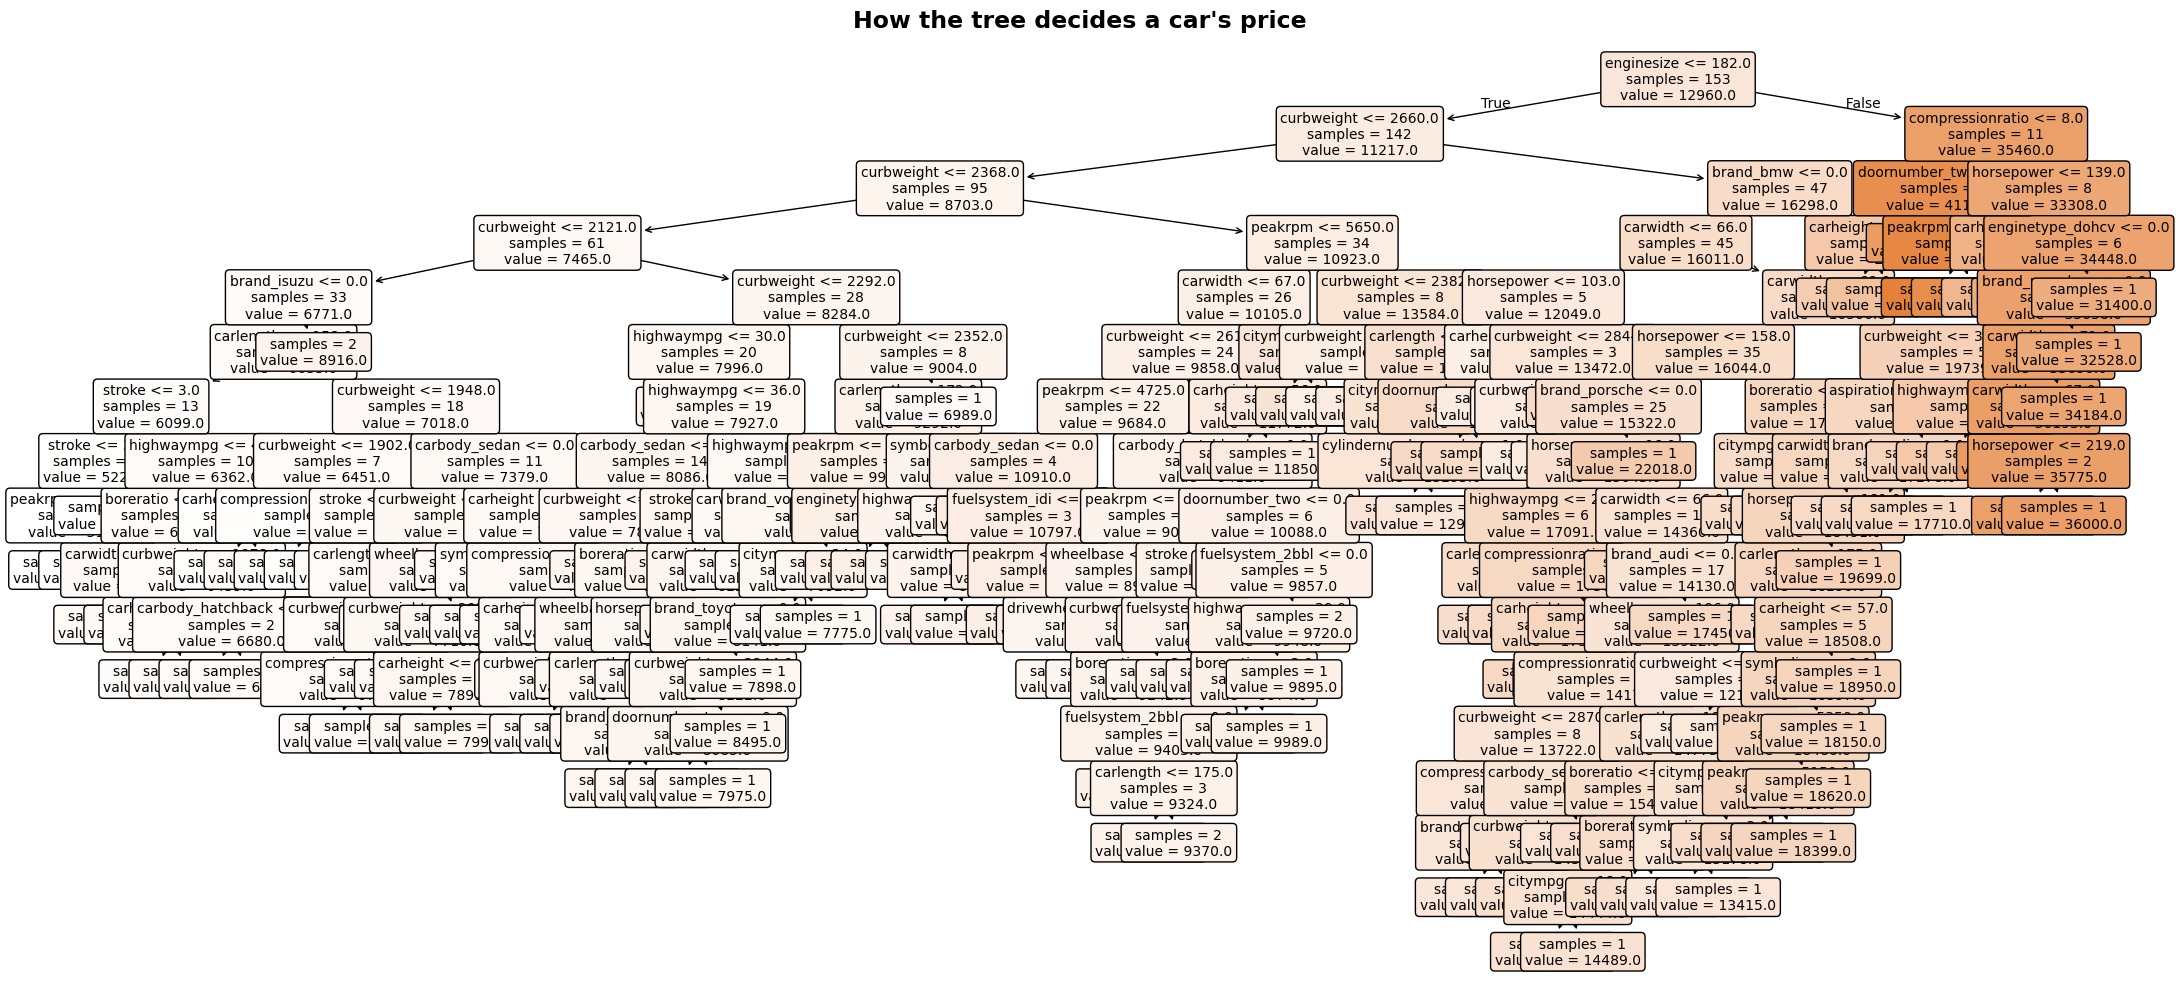

In [87]:
fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(
    model,
    feature_names=list(X.columns),
    filled=True,            # colour the boxes: darker = more expensive cars
    impurity=False,         # hide a technical score we don't need today
    rounded=True,
    fontsize=10,
    precision=0,
    ax=ax,
)
ax.set_title("How the tree decides a car's price", fontsize=17, fontweight="bold", pad=18)
plt.tight_layout()
plt.show()

In [88]:
Y_prediction = model.predict(X_test)

In [89]:
MAE = mean_absolute_error(Y_test, Y_prediction)

In [90]:
MAE

2188.291673076923

In [91]:
r2 = r2_score(Y_test, Y_prediction)

In [92]:
r2

0.8769763358101155